# Étude de la sous-nutrition dans le monde (FAO, 2013 à 2017)

Étude de santé publique réalisée à partir de quatre extraits de FAOSTAT : population, disponibilité alimentaire, sous-nutrition et aide alimentaire.

**Questions traitées**

1. Quelle part de la population mondiale est sous-nutrie en 2017 ?
2. La production mondiale suffirait-elle à nourrir tout le monde ? Et avec les seuls végétaux ?
3. À quoi sert la disponibilité alimentaire mondiale, et en particulier les céréales ?
4. Quels pays sont les plus touchés, lesquels reçoivent le plus d'aide, lesquels disposent du plus et du moins de calories ?
5. Étude de cas : la Thaïlande et le manioc.

**Sommaire** : 1. Chargement · 2. Préparation des données · 3. Analyses · 4. Carte · 5. Synthèse

## 1. Chargement des données

In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import requests
import seaborn as sns

DATA_DIR = Path("../data")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

# Besoin énergétique moyen retenu pour un adulte (kcal par jour)
SEUIL_KCAL = 2500

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
population = pd.read_csv(DATA_DIR / "population.csv")
dispo = pd.read_csv(DATA_DIR / "dispo_alimentaire.csv")
aide = pd.read_csv(DATA_DIR / "aide_alimentaire.csv")
sous_nutrition = pd.read_csv(DATA_DIR / "sous_nutrition.csv")
iso = pd.read_csv(DATA_DIR / "zone_iso3.csv")


def apercu(df, nom):
    """Dimensions, valeurs manquantes et doublons d'un fichier."""
    print(f"{nom} : {df.shape[0]} lignes, {df.shape[1]} colonnes, "
          f"{df.duplicated().sum()} doublon(s)")
    manquants = df.isna().sum()
    if manquants.any():
        print("  valeurs manquantes :", manquants[manquants > 0].to_dict())


for df, nom in [(population, "population"), (dispo, "dispo_alimentaire"),
                (aide, "aide_alimentaire"), (sous_nutrition, "sous_nutrition")]:
    apercu(df, nom)

population : 1416 lignes, 3 colonnes, 0 doublon(s)
dispo_alimentaire : 15605 lignes, 18 colonnes, 0 doublon(s)
  valeurs manquantes : {'Aliments pour animaux': 12885, 'Autres Utilisations': 10109, 'Disponibilité alimentaire (Kcal/personne/jour)': 1364, 'Disponibilité alimentaire en quantité (kg/personne/an)': 1590, 'Disponibilité de matière grasse en quantité (g/personne/jour)': 3811, 'Disponibilité de protéines en quantité (g/personne/jour)': 4044, 'Disponibilité intérieure': 223, 'Exportations - Quantité': 3379, 'Importations - Quantité': 753, 'Nourriture': 1590, 'Pertes': 11327, 'Production': 6425, 'Semences': 13514, 'Traitement': 13313, 'Variation de stock': 8829}
aide_alimentaire : 1475 lignes, 4 colonnes, 0 doublon(s)
sous_nutrition : 1218 lignes, 3 colonnes, 0 doublon(s)
  valeurs manquantes : {'Valeur': 594}


## 2. Préparation des données

Toutes les quantités sont ramenées dans la même unité (personnes et kilogrammes) avant les calculs, pour éviter de mélanger des milliers de tonnes et des tonnes.

### 2.1 Population

La population est exprimée en milliers d'habitants : conversion en nombre d'habitants.

In [3]:
population["Valeur"] = population["Valeur"] * 1000
population = population.rename(columns={"Valeur": "Population"})
population_2017 = population[population["Année"] == 2017][["Zone", "Population"]]

print(f"{population['Zone'].nunique()} zones, années {population['Année'].min()} à {population['Année'].max()}")
population_2017.head()

236 zones, années 2013 à 2018


,Zone,Population
4,Afghanistan,36296113.0
10,Afrique du Sud,57009756.0
16,Albanie,2884169.0
22,Algérie,41389189.0
28,Allemagne,82658409.0


### 2.2 Disponibilité alimentaire

Une ligne par pays et par produit, pour 2017. Les quantités sont en milliers de tonnes. Une valeur absente signifie que le flux n'existe pas pour ce produit (pas d'export, pas de semences...) : elle est remplacée par 0.

In [4]:
dispo = dispo.fillna(0)

colonnes_milliers_tonnes = [
    "Aliments pour animaux", "Autres Utilisations", "Disponibilité intérieure",
    "Exportations - Quantité", "Importations - Quantité", "Nourriture",
    "Pertes", "Production", "Semences", "Traitement", "Variation de stock",
]
dispo[colonnes_milliers_tonnes] = dispo[colonnes_milliers_tonnes] * 1_000_000

print(f"{dispo['Zone'].nunique()} pays, {dispo['Produit'].nunique()} produits")
dispo.head()

174 pays, 98 produits


,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000000.0,0.0,0.0,53000000.0,0.0,53000000.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000000.0,2000000.0,40000000.0,39000000.0,2000000.0,3000000.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000000.0,0.0,2000000.0,2000000.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000000.0,0.0,82000000.0,82000000.0,0.0,0.0,0.0,0.0,0.0


### 2.3 Aide alimentaire

Quantités en tonnes, par pays bénéficiaire, produit et année (2013 à 2016) : conversion en kilogrammes.

In [5]:
aide = aide.rename(columns={"Pays bénéficiaire": "Zone"})
aide["Valeur"] = aide["Valeur"] * 1000

print(f"{aide['Zone'].nunique()} pays bénéficiaires, années {aide['Année'].min()} à {aide['Année'].max()}")
aide.head()

76 pays bénéficiaires, années 2013 à 2016


,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


### 2.4 Sous-nutrition

Nombre de personnes sous-nutries en millions, en moyenne sur trois ans. La période 2016-2018 est centrée sur 2017 : c'est elle qui sert d'estimation pour 2017.

La FAO publie `<0.1` quand le nombre est inférieur à 100 000 personnes. Ces valeurs ne sont pas chiffrables précisément : elles sont exclues du total, ce qui sous-estime le total mondial d'au plus 100 000 personnes par pays concerné.

In [6]:
periode_2017 = sous_nutrition["Année"] == "2016-2018"
nb_inf_01 = (periode_2017 & (sous_nutrition["Valeur"] == "<0.1")).sum()

sous_nutrition["Valeur"] = pd.to_numeric(sous_nutrition["Valeur"], errors="coerce") * 1_000_000
sous_nutrition = sous_nutrition.rename(columns={"Valeur": "sous_nutrition"})
sous_nutrition_2017 = sous_nutrition[periode_2017].dropna(subset=["sous_nutrition"])

print(f"Pays avec une estimation chiffrée en 2017 : {len(sous_nutrition_2017)}")
print(f"Pays à moins de 100 000 personnes (<0.1), exclus du total : {nb_inf_01}")
print(f"Impact maximal sur le total mondial : {nb_inf_01 * 100_000:,.0f} personnes".replace(",", " "))

Pays avec une estimation chiffrée en 2017 : 84
Pays à moins de 100 000 personnes (<0.1), exclus du total : 20
Impact maximal sur le total mondial : 2 000 000 personnes


## 3. Analyses

### 3.1 Proportion de personnes sous-nutries en 2017

In [7]:
prop_2017 = population_2017.merge(sous_nutrition_2017[["Zone", "sous_nutrition"]],
                                  on="Zone", how="left")
prop_2017["proportion"] = prop_2017["sous_nutrition"] / prop_2017["Population"] * 100

population_mondiale = prop_2017["Population"].sum()
total_sous_nutris = prop_2017["sous_nutrition"].sum()
proportion_mondiale = total_sous_nutris / population_mondiale * 100

print(f"Population mondiale 2017 : {population_mondiale:,.0f}".replace(",", " "))
print(f"Personnes sous-nutries   : {total_sous_nutris:,.0f}".replace(",", " "))
print(f"Proportion               : {proportion_mondiale:.1f} %")

Population mondiale 2017 : 7 548 134 111
Personnes sous-nutries   : 535 700 000
Proportion               : 7.1 %


### 3.2 Nombre théorique de personnes qui pourraient être nourries

Calories disponibles par pays = disponibilité par habitant et par jour (somme sur tous les produits) × population. Le total mondial est divisé par le besoin moyen retenu (`SEUIL_KCAL`).

In [8]:
dispo = dispo.merge(population_2017, on="Zone", how="left")
dispo["kcal_jour"] = dispo["Disponibilité alimentaire (Kcal/personne/jour)"] * dispo["Population"]

personnes_nourries = dispo["kcal_jour"].sum() / SEUIL_KCAL
part_nourrie = personnes_nourries / population_mondiale * 100

print(f"Personnes pouvant être nourries : {personnes_nourries:,.0f}".replace(",", " "))
print(f"Soit {part_nourrie:.1f} % de la population mondiale")

Personnes pouvant être nourries : 8 367 593 851
Soit 110.9 % de la population mondiale


### 3.3 Même calcul avec les seuls produits végétaux

In [9]:
dispo_vegetale = dispo[dispo["Origine"] == "vegetale"]
personnes_nourries_veg = dispo_vegetale["kcal_jour"].sum() / SEUIL_KCAL
part_nourrie_veg = personnes_nourries_veg / population_mondiale * 100

print(f"Personnes pouvant être nourries avec les végétaux : {personnes_nourries_veg:,.0f}".replace(",", " "))
print(f"Soit {part_nourrie_veg:.1f} % de la population mondiale")

Personnes pouvant être nourries avec les végétaux : 6 904 305 685
Soit 91.5 % de la population mondiale


### 3.4 Utilisation de la disponibilité intérieure

La disponibilité intérieure (production + importations − exportations + variation de stock) se répartit entre six usages.

In [10]:
USAGES = {
    "Nourriture": "Nourriture humaine",
    "Aliments pour animaux": "Alimentation animale",
    "Traitement": "Traitement",
    "Autres Utilisations": "Autres usages",
    "Pertes": "Pertes",
    "Semences": "Semences",
}


def repartition_usages(df):
    """Part de chaque usage dans la disponibilité intérieure, en %."""
    total = df["Disponibilité intérieure"].sum()
    parts = df[list(USAGES)].sum() / total * 100
    return parts.rename(USAGES).sort_values(ascending=False)


usages_monde = repartition_usages(dispo)
usages_monde.round(1)

Nourriture humaine      49.5
Traitement              22.4
Alimentation animale    13.2
Autres usages            8.8
Pertes                   4.6
Semences                 1.6
dtype: float64

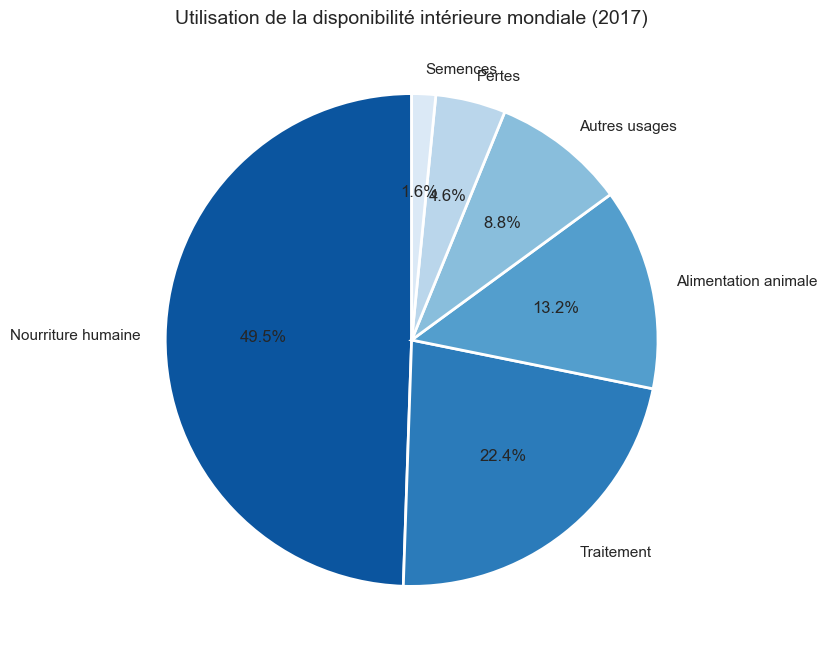

In [11]:
def camembert(parts, titre, palette, fichier):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(parts.values, labels=parts.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette(palette, len(parts)),
           wedgeprops={"edgecolor": "white", "linewidth": 2})
    ax.set_title(titre, fontsize=14)
    fig.savefig(IMG_DIR / fichier, dpi=150, bbox_inches="tight")
    plt.show()


camembert(usages_monde, "Utilisation de la disponibilité intérieure mondiale (2017)",
          "Blues_r", "02_repartition_dispo.png")

### 3.5 Utilisation des céréales

Céréales pour l'alimentation humaine : 42.8 %
Céréales pour l'alimentation animale : 36.3 %


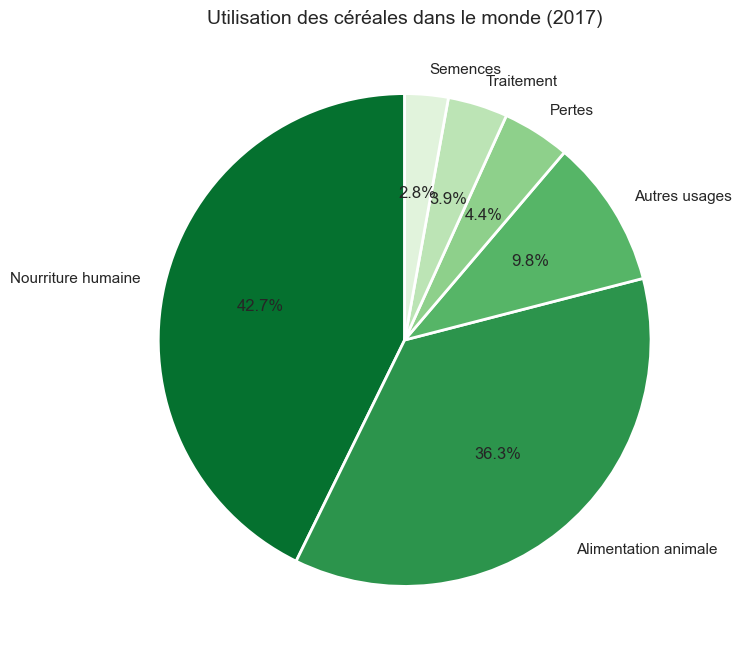

In [12]:
CEREALES = ["Blé", "Maïs", "Riz (Eq Blanchi)", "Orge", "Millet",
            "Avoine", "Seigle", "Sorgho", "Céréales, Autres"]

usages_cereales = repartition_usages(dispo[dispo["Produit"].isin(CEREALES)])
print(f"Céréales pour l'alimentation humaine : {usages_cereales['Nourriture humaine']:.1f} %")
print(f"Céréales pour l'alimentation animale : {usages_cereales['Alimentation animale']:.1f} %")

camembert(usages_cereales, "Utilisation des céréales dans le monde (2017)",
          "Greens_r", "03_cereales.png")

### 3.6 Pays avec la plus forte proportion de personnes sous-nutries en 2017

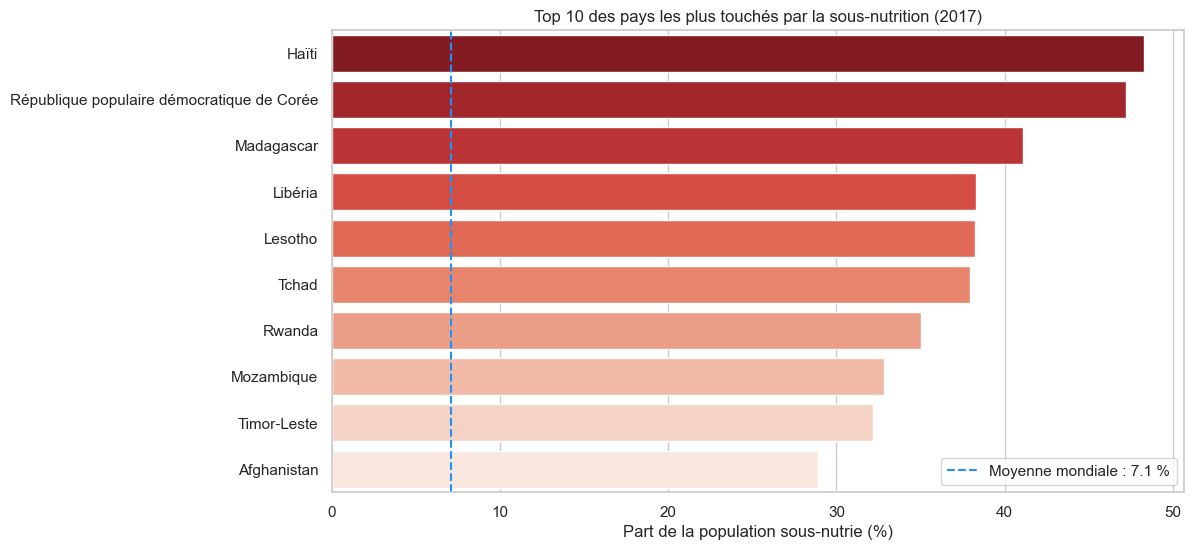

,Zone,Population,sous_nutrition,proportion
87,Haïti,10982366.0,5300000.0,48.3
181,République populaire démocratique de Corée,25429825.0,12000000.0,47.2
128,Madagascar,25570512.0,10500000.0,41.1
122,Libéria,4702226.0,1800000.0,38.3
119,Lesotho,2091534.0,800000.0,38.2
216,Tchad,15016753.0,5700000.0,38.0
186,Rwanda,11980961.0,4200000.0,35.1
145,Mozambique,28649018.0,9400000.0,32.8
219,Timor-Leste,1243258.0,400000.0,32.2
0,Afghanistan,36296113.0,10500000.0,28.9


In [13]:
top10_proportion = prop_2017.nlargest(10, "proportion")[["Zone", "Population", "sous_nutrition", "proportion"]]

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top10_proportion, x="proportion", y="Zone", hue="Zone",
            palette="Reds_r", legend=False, ax=ax)
ax.axvline(proportion_mondiale, color="dodgerblue", linestyle="--",
           label=f"Moyenne mondiale : {proportion_mondiale:.1f} %")
ax.set(title="Top 10 des pays les plus touchés par la sous-nutrition (2017)",
       xlabel="Part de la population sous-nutrie (%)", ylabel="")
ax.legend()
fig.savefig(IMG_DIR / "01_top10_sous_nutrition.png", dpi=150, bbox_inches="tight")
plt.show()

top10_proportion.round(1)

### 3.7 Pays qui ont reçu le plus d'aide alimentaire depuis 2013

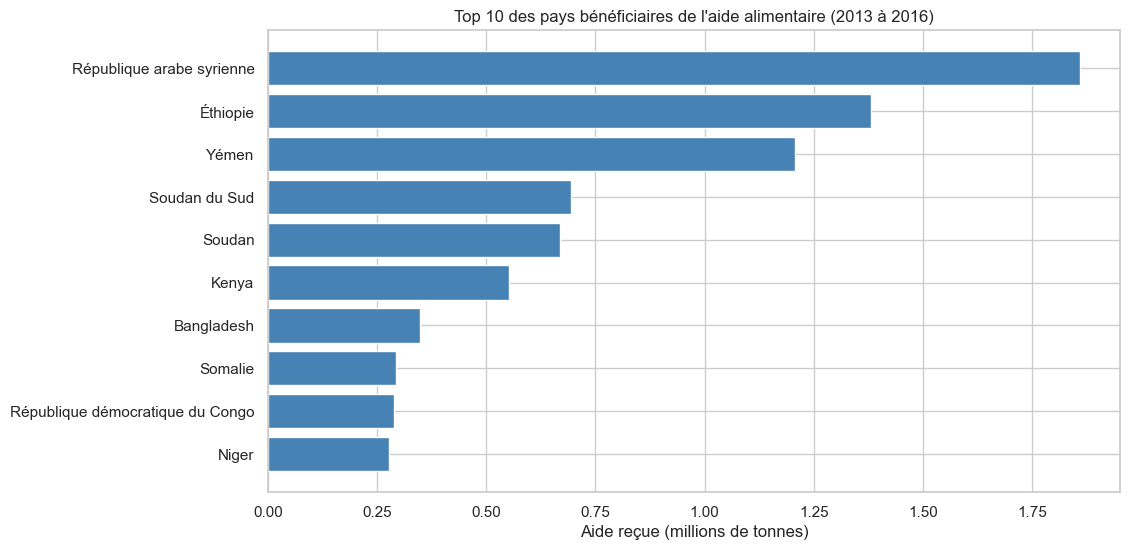

Zone
République arabe syrienne           1859.0
Éthiopie                            1381.0
Yémen                               1206.0
Soudan du Sud                        695.0
Soudan                               670.0
Kenya                                553.0
Bangladesh                           348.0
Somalie                              293.0
République démocratique du Congo     289.0
Niger                                276.0
Name: Aide reçue (milliers de tonnes), dtype: float64

In [14]:
aide_par_pays = aide.groupby("Zone")["Valeur"].sum().sort_values(ascending=False)
top10_aide = aide_par_pays.head(10)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10_aide.index[::-1], top10_aide.values[::-1] / 1e9, color="steelblue")
ax.set(title="Top 10 des pays bénéficiaires de l'aide alimentaire (2013 à 2016)",
       xlabel="Aide reçue (millions de tonnes)")
fig.savefig(IMG_DIR / "05_top10_aide.png", dpi=150, bbox_inches="tight")
plt.show()

(top10_aide / 1e6).round(0).rename("Aide reçue (milliers de tonnes)")

### 3.8 Évolution de l'aide pour les 5 premiers bénéficiaires

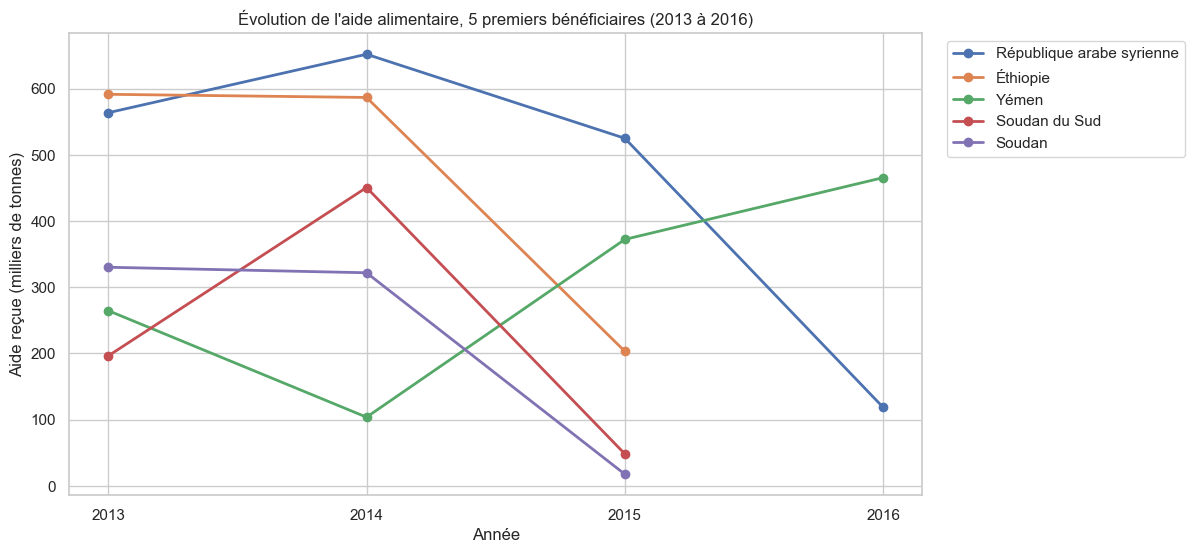

Année,2013,2014,2015,2016
Zone,,,,
République arabe syrienne,564.0,652.0,525.0,119.0
Soudan,330.0,322.0,18.0,NaN
Soudan du Sud,196.0,451.0,48.0,NaN
Yémen,265.0,104.0,372.0,466.0
Éthiopie,591.0,587.0,203.0,NaN


In [15]:
top5 = top10_aide.head(5).index
aide_top5 = (aide[aide["Zone"].isin(top5)]
             .groupby(["Zone", "Année"])["Valeur"].sum()
             .unstack("Année") / 1e6)

fig, ax = plt.subplots(figsize=(11, 6))
for pays in top5:
    ax.plot(aide_top5.columns, aide_top5.loc[pays], marker="o", linewidth=2, label=pays)
ax.set(title="Évolution de l'aide alimentaire, 5 premiers bénéficiaires (2013 à 2016)",
       xlabel="Année", ylabel="Aide reçue (milliers de tonnes)")
ax.set_xticks(aide_top5.columns)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.savefig(IMG_DIR / "04_evolution_aide.png", dpi=150, bbox_inches="tight")
plt.show()

aide_top5.round(0)

### 3.9 et 3.10 Disponibilité alimentaire par habitant

Somme des calories disponibles par habitant et par jour sur tous les produits d'un pays.

Moyenne des pays : 2847 kcal par habitant et par jour
Écart entre le pays le mieux et le moins bien pourvu : x2.0


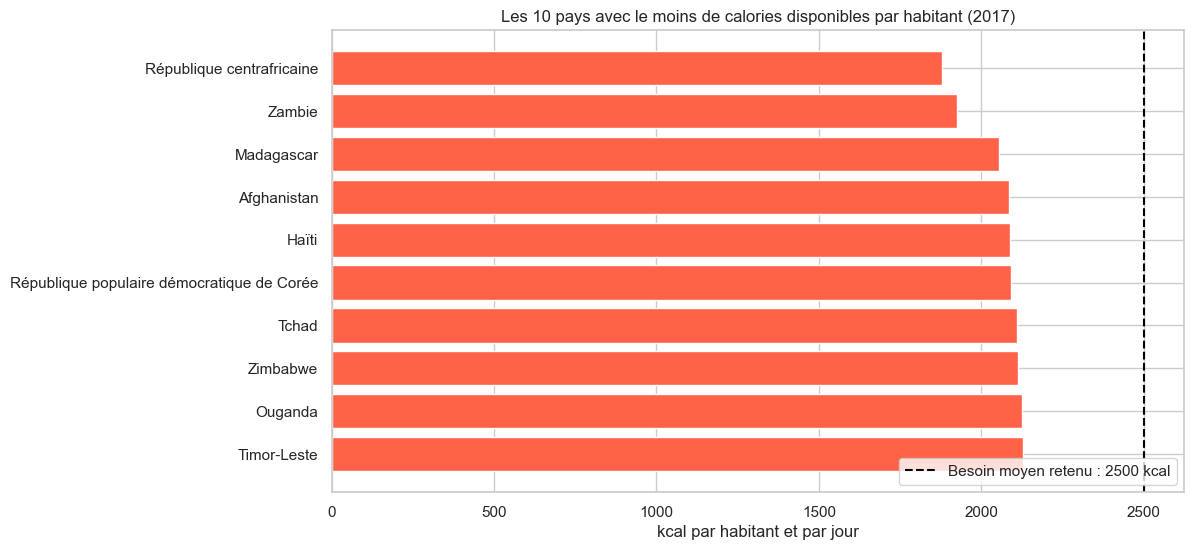

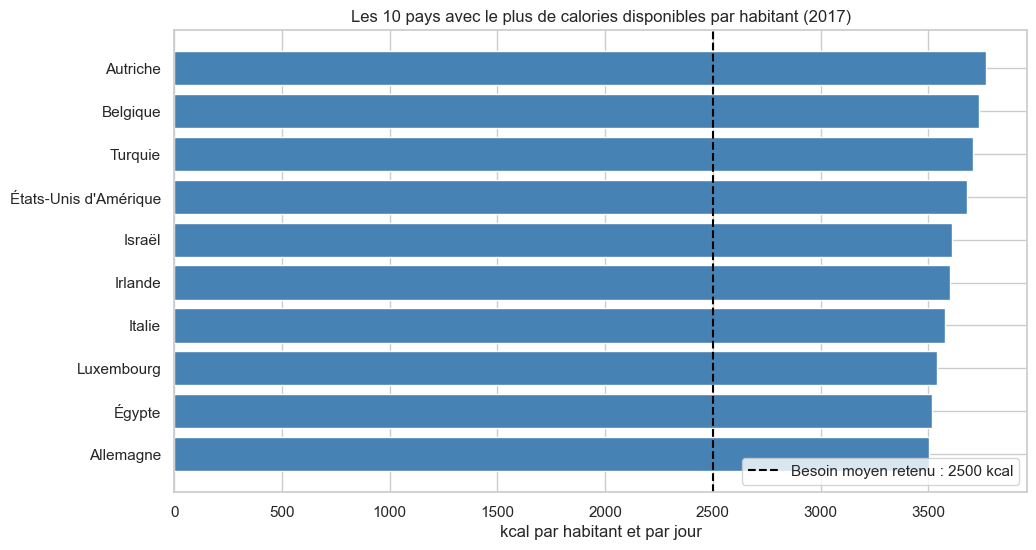

In [16]:
kcal_par_pays = (dispo.groupby("Zone")["Disponibilité alimentaire (Kcal/personne/jour)"]
                 .sum().rename("kcal_hab_jour").sort_values())
moyenne_pays = kcal_par_pays.mean()
print(f"Moyenne des pays : {moyenne_pays:.0f} kcal par habitant et par jour")
print(f"Écart entre le pays le mieux et le moins bien pourvu : x{kcal_par_pays.iloc[-1] / kcal_par_pays.iloc[0]:.1f}")


def barres_kcal(serie, titre, couleur, fichier):
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(serie.index, serie.values, color=couleur)
    ax.axvline(SEUIL_KCAL, color="black", linestyle="--", label=f"Besoin moyen retenu : {SEUIL_KCAL} kcal")
    ax.set(title=titre, xlabel="kcal par habitant et par jour")
    ax.legend(loc="lower right")
    fig.savefig(IMG_DIR / fichier, dpi=150, bbox_inches="tight")
    plt.show()


barres_kcal(kcal_par_pays.head(10)[::-1], "Les 10 pays avec le moins de calories disponibles par habitant (2017)",
            "tomato", "07_bottom10_dispo.png")
barres_kcal(kcal_par_pays.tail(10), "Les 10 pays avec le plus de calories disponibles par habitant (2017)",
            "steelblue", "06_top10_dispo.png")

### 3.11 Étude de cas : la Thaïlande et le manioc

La Thaïlande est un grand producteur de manioc. Quelle part de sa production est exportée, alors qu'une partie de sa population est sous-nutrie ?

In [17]:
manioc_thai = dispo[(dispo["Zone"] == "Thaïlande") & (dispo["Produit"] == "Manioc")].iloc[0]
part_exportee = manioc_thai["Exportations - Quantité"] / manioc_thai["Production"] * 100
sous_nutrition_thai = prop_2017.loc[prop_2017["Zone"] == "Thaïlande", "proportion"].iloc[0]

print(f"Production de manioc : {manioc_thai['Production'] / 1e9:.1f} millions de tonnes")
print(f"Part exportée        : {part_exportee:.1f} %")
print(f"Population sous-nutrie en Thaïlande : {sous_nutrition_thai:.1f} %")

Production de manioc : 30.2 millions de tonnes
Part exportée        : 83.4 %
Population sous-nutrie en Thaïlande : 9.0 %


## 4. Carte de la sous-nutrition en 2017

Les noms de pays FAO sont en français : ils sont reliés aux codes ISO 3166 par une table de correspondance vérifiée à la main (`data/zone_iso3.csv`). Une correspondance automatique par similarité de nom donnait des erreurs (l'Inde reconnue comme la Papouasie-Nouvelle-Guinée, le Niger comme le Nigéria).

In [18]:
carte = prop_2017.merge(iso, left_on="Zone", right_on="zone", how="left")
sans_code = carte.loc[carte["iso3"].isna(), "Zone"].tolist()
print(f"Zones sans code ISO (non affichées) : {sans_code}")
assert not carte["iso3"].dropna().duplicated().any(), "Un code ISO est attribué à deux zones"

fig = px.choropleth(carte.dropna(subset=["proportion"]), locations="iso3", color="proportion",
                    hover_name="Zone", color_continuous_scale="YlOrRd",
                    labels={"proportion": "Sous-nutrition (%)"},
                    title="Part de la population sous-nutrie en 2017")
fig.update_geos(projection_type="natural earth", showframe=False, lataxis_range=[-58, 85])
fig.update_layout(width=1000, height=520, margin=dict(l=0, r=0, t=50, b=0))
fig.write_image(IMG_DIR / "08_carte_sous_nutrition.png", scale=2)
fig.show()

Zones sans code ISO (non affichées) : ['Antilles néerlandaises (ex)', 'Îles Anglo-Normandes']


In [19]:
# Version interactive (Folium), exportée en HTML pour la présentation
geojson = requests.get(
    "https://raw.githubusercontent.com/python-visualization/folium/main/examples/data/world-countries.json",
    timeout=30,
).json()

m = folium.Map(location=[20, 0], zoom_start=2, tiles="CartoDB positron")
folium.Choropleth(
    geo_data=geojson,
    data=carte.dropna(subset=["proportion", "iso3"]),
    columns=["iso3", "proportion"],
    key_on="feature.id",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.2,
    nan_fill_color="lightgrey",
    legend_name="Part de la population sous-nutrie en 2017 (%)",
).add_to(m)
m.save(IMG_DIR / "08_carte_sous_nutrition.html")
m

## 5. Synthèse

In [20]:
print(f"Personnes sous-nutries en 2017 : {total_sous_nutris / 1e6:,.1f} millions ({proportion_mondiale:.1f} % de la population)")
print(f"La disponibilité mondiale nourrirait {part_nourrie:.1f} % de la population, {part_nourrie_veg:.1f} % avec les seuls végétaux")
print(f"Moins de la moitié de la disponibilité intérieure va à l'alimentation humaine : {usages_monde['Nourriture humaine']:.1f} %")
print(f"Céréales : {usages_cereales['Nourriture humaine']:.1f} % pour les humains, {usages_cereales['Alimentation animale']:.1f} % pour les animaux")
print(f"Pays le plus touché : {top10_proportion.iloc[0]['Zone']} ({top10_proportion.iloc[0]['proportion']:.1f} %)")
print(f"Thaïlande : {part_exportee:.1f} % du manioc exporté, {sous_nutrition_thai:.1f} % de la population sous-nutrie")

Personnes sous-nutries en 2017 : 535.7 millions (7.1 % de la population)
La disponibilité mondiale nourrirait 110.9 % de la population, 91.5 % avec les seuls végétaux
Moins de la moitié de la disponibilité intérieure va à l'alimentation humaine : 49.5 %
Céréales : 42.8 % pour les humains, 36.3 % pour les animaux
Pays le plus touché : Haïti (48.3 %)
Thaïlande : 83.4 % du manioc exporté, 9.0 % de la population sous-nutrie


**Conclusion** : la quantité de nourriture disponible dans le monde dépasse les besoins de la population. La sous-nutrition est d'abord un problème de **répartition et d'accès** : conflits, revenus, dépendance aux marchés, pertes après récolte. Les pays les plus touchés ne se ressemblent pas tous, ce qui appelle des réponses différentes selon leur profil.